# Onde está o faturamento de 2025?

Objetivo: mostrar à diretoria comercial o faturamento por região, por mês e por canal de venda, para decidir onde concentrar o esforço em 2026.

Faturamento = quantidade × preço unitário.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

def reais(v):
    return f"R$ {v:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")

In [2]:
df = pd.read_csv("dados/vendas.csv")
print(df.shape)
df.head()

(5000, 8)


,data,produto,categoria,regiao,quantidade,preco_unitario,custo_unitario,canal_venda
0,2025-01-01,Mouse,Acessórios,Centro-Oeste,5,52.97,30.53,Online
1,2025-01-01,Monitor,Eletrônicos,Sul,7,1118.13,765.68,Loja física
2,2025-01-01,Tablet,Eletrônicos,Centro-Oeste,6,1611.59,959.28,Marketplace
3,2025-01-01,Monitor,Eletrônicos,Nordeste,4,953.18,559.37,Loja física
4,2025-01-01,Teclado,Acessórios,Sul,6,174.44,124.57,Online


## O arquivo foi lido corretamente?
Vamos conferir o tamanho, os tipos de cada coluna e os nomes das categorias.

In [3]:
df.dtypes.to_frame("tipo")

,tipo
data,str
produto,str
categoria,str
regiao,str
quantidade,int64
preco_unitario,float64
custo_unitario,float64
canal_venda,str


In [4]:
for c in ["regiao", "canal_venda", "categoria", "produto"]:
    print(c, sorted(df[c].dropna().unique()))

regiao ['Centro-Oeste', 'Nordeste', 'Norte', 'Sudeste', 'Sul']
canal_venda ['Loja física', 'Marketplace', 'Online']
categoria ['Acessórios', 'Eletrônicos', 'Móveis']
produto ['Cadeira', 'Estante', 'Gaveteiro', 'Headset', 'Mesa', 'Monitor', 'Mouse', 'Notebook', 'Smartphone', 'Tablet', 'Teclado', 'Webcam']


## Há linhas repetidas ou dados faltando?
Vamos contar linhas duplicadas e células vazias em cada coluna.

In [5]:
print("duplicadas:", df.duplicated().sum())
df.isna().sum().to_frame("faltando")

duplicadas: 0


,faltando
data,0
produto,0
categoria,0
regiao,154
quantidade,0
preco_unitario,0
custo_unitario,0
canal_venda,0


In [6]:
df[["quantidade", "preco_unitario", "custo_unitario"]].describe().T

,count,mean,std,min,25%,50%,75%,max
quantidade,5000.0,5.242400,2.842122,1.00,3.0000,5.000,8.0000,10.00
preco_unitario,5000.0,1011.605108,976.758235,50.10,306.1200,637.000,1400.7725,3599.30
custo_unitario,5000.0,643.894572,626.428442,28.84,192.2275,402.055,852.2525,2577.01


## Qual o período dos dados e há preços ou quantidades impossíveis?
Vamos converter a data, ver o primeiro e o último dia, e checar se algum preço está abaixo do custo. Depois calculamos o faturamento de cada venda e vemos de onde vem a falta de região.

In [7]:
df["data"] = pd.to_datetime(df["data"], format="%Y-%m-%d")
print(df["data"].min(), df["data"].max())
print("preço abaixo do custo:", (df["preco_unitario"] < df["custo_unitario"]).sum())
df["data"].dt.to_period("M").value_counts().sort_index().to_frame("vendas")

2025-01-01 00:00:00 2025-12-31 00:00:00
preço abaixo do custo: 0


,vendas
data,
2025-01,243
2025-02,249
2025-03,362
2025-04,335
2025-05,393
2025-06,358
2025-07,383
2025-08,435
2025-09,411


In [8]:
df["faturamento"] = df["quantidade"] * df["preco_unitario"]
sem = df[df["regiao"].isna()]
print(f"{sem['faturamento'].sum() / df['faturamento'].sum():.1%} do faturamento")
pd.concat([sem["canal_venda"].value_counts(normalize=True).rename("canal"),
           df["canal_venda"].value_counts(normalize=True).rename("total")], axis=1)

2.9% do faturamento


,canal,total
canal_venda,,
Online,0.461039,0.4426
Loja física,0.292208,0.3122
Marketplace,0.246753,0.2452


## Os dados estão confiáveis para responder à pergunta?

**Resultado:** o arquivo cobre todo 2025 (1º de janeiro a 31 de dezembro), sem linhas repetidas, sem valores impossíveis e sem preço abaixo do custo. O único problema é que `154` vendas (`2,9%` do faturamento) não têm região, espalhadas por todos os canais.

**Decisão:** manter essas vendas num grupo chamado "Sem região informada". Assim o total do ano fecha e a diretoria vê o tamanho da lacuna, em vez de ela sumir.

In [9]:
df["regiao"] = df["regiao"].fillna("Sem região informada")
df["mes"] = df["data"].dt.month
df[["regiao", "mes", "faturamento"]].sample(5, random_state=1)

,regiao,mes,faturamento
2764,Nordeste,9,931.12
4767,Nordeste,12,8147.88
3814,Centro-Oeste,11,17052.57
3499,Sul,10,438.70
2735,Sul,8,2120.12


## Quanto faturamos em 2025 e qual região vende mais?
Vamos somar o faturamento do ano e dividir por região, com a participação de cada uma e o número de vendas.

In [10]:
total = df["faturamento"].sum()
print("Faturamento 2025:", reais(total))
reg = df.groupby("regiao")["faturamento"].agg(total="sum", vendas="count").sort_values("total", ascending=False)
reg["participação"] = (reg["total"] / total).map("{:.1%}".format)
reg["ticket médio"] = (reg["total"] / reg["vendas"]).map(reais)
reg.assign(total=reg["total"].map(reais))

Faturamento 2025: R$ 25.016.139,62


,total,vendas,participação,ticket médio
regiao,,,,
Sudeste,"R$ 9.827.937,32",1933,39.3%,"R$ 5.084,29"
Sul,"R$ 4.380.944,08",875,17.5%,"R$ 5.006,79"
Nordeste,"R$ 4.140.642,33",857,16.6%,"R$ 4.831,55"
Centro-Oeste,"R$ 3.086.274,60",590,12.3%,"R$ 5.230,97"
Norte,"R$ 2.854.711,86",591,11.4%,"R$ 4.830,31"
Sem região informada,"R$ 725.629,43",154,2.9%,"R$ 4.711,88"


**Resultado:** o ano fechou em `R$ 25,0 milhões`, e o Sudeste responde por `39%` disso, mais que o dobro do Sul, o segundo colocado.

O Sudeste vende mais por volume: tem `1.933` vendas, contra `590` a `875` nas outras regiões. O valor médio por venda é parecido em todas (entre `R$ 4.800` e `R$ 5.200`). Ou seja, o Sudeste não vende melhor por venda, vende mais vezes.

Esses dados mostram onde o dinheiro entrou, não onde há mais mercado a explorar. Não temos o tamanho do mercado de cada região, então não dá para dizer que Norte e Centro-Oeste estão "abaixo do potencial".

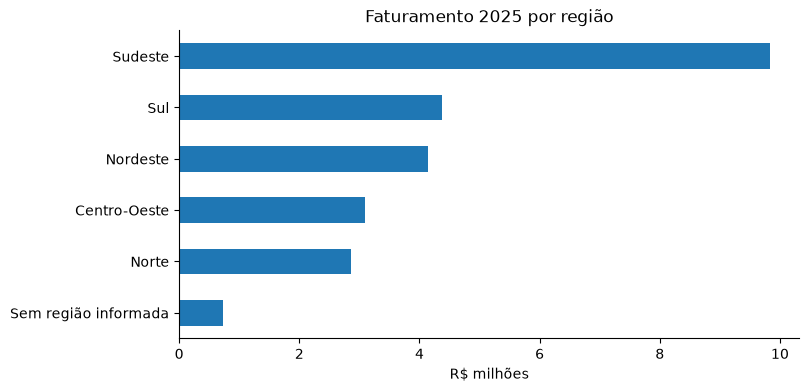

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
(reg["total"].sort_values() / 1e6).plot.barh(ax=ax, color="#1f77b4")
ax.set(title="Faturamento 2025 por região", xlabel="R$ milhões", ylabel="")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## Em quais meses o faturamento se concentra?
Vamos somar o faturamento de cada mês e ver quanto cada um pesa no ano.

In [17]:
mes = df.groupby("mes")["faturamento"].sum()
dias = pd.Series(range(1, 13), index=range(1, 13)).map(lambda m: pd.Period(f"2025-{m:02d}").days_in_month)
tab = pd.DataFrame({"total": mes.map(reais), "participação": (mes / total).map("{:.1%}".format),
                    "por dia": (mes / dias).map(reais), "vendas": df.groupby("mes").size()})
print("Nov+Dez:", f"{mes[[11, 12]].sum() / total:.1%}", "| Jan+Fev:", f"{mes[[1, 2]].sum() / total:.1%}")
tab

Nov+Dez: 28.6% | Jan+Fev: 9.8%


,total,participação,por dia,vendas
mes,,,,
1,"R$ 1.108.186,68",4.4%,"R$ 35.747,96",243
2,"R$ 1.341.894,08",5.4%,"R$ 47.924,79",249
3,"R$ 1.740.646,35",7.0%,"R$ 56.149,88",362
4,"R$ 1.715.094,81",6.9%,"R$ 57.169,83",335
5,"R$ 1.896.748,57",7.6%,"R$ 61.185,44",393
6,"R$ 1.681.848,24",6.7%,"R$ 56.061,61",358
7,"R$ 1.991.033,83",8.0%,"R$ 64.226,90",383
8,"R$ 2.073.660,68",8.3%,"R$ 66.892,28",435
9,"R$ 2.108.096,79",8.4%,"R$ 70.269,89",411


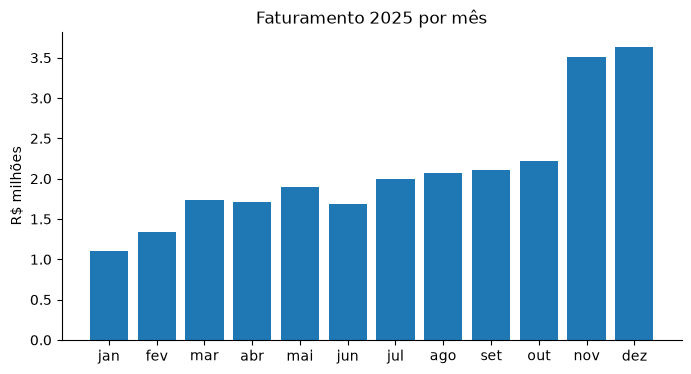

In [13]:
nomes = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(nomes, mes / 1e6, color="#1f77b4")
ax.set(title="Faturamento 2025 por mês", ylabel="R$ milhões")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Resultado:** o faturamento sobe ao longo do ano e dá um salto em novembro e dezembro, que juntos concentram `28,6%` do ano (`R$ 7,1 milhões`). Janeiro e fevereiro são os mais fracos, juntos `9,8%`.

Como os meses têm tamanhos diferentes, conferimos também o faturamento por dia: o desenho não muda. Novembro e dezembro rendem cerca de `R$ 117 mil` por dia, contra `R$ 71 mil` em outubro. Janeiro (`R$ 36 mil` por dia) e fevereiro (`R$ 48 mil`) continuam os mais baixos. O salto vem de mais vendas (`654` e `745` em novembro e dezembro, contra `432` em outubro).

Temos só um ano de dados, então não dá para saber se o salto no fim do ano é um padrão que se repete (Black Friday e Natal, por exemplo) ou crescimento real do negócio. Para planejar 2026, a leitura prudente é tratar novembro e dezembro como um pico de calendário que exige estoque e equipe, e confirmar com os anos anteriores.

## Qual canal de venda traz mais faturamento?
Vamos comparar Online, Loja física e Marketplace: faturamento, participação, número de vendas e valor médio por venda.

In [14]:
can = df.groupby("canal_venda")["faturamento"].agg(total="sum", vendas="count").sort_values("total", ascending=False)
can["participação"] = (can["total"] / total).map("{:.1%}".format)
can["ticket médio"] = (can["total"] / can["vendas"]).map(reais)
can.assign(total=can["total"].map(reais))

,total,vendas,participação,ticket médio
canal_venda,,,,
Online,"R$ 11.155.638,64",2213,44.6%,"R$ 5.040,96"
Loja física,"R$ 7.982.486,44",1561,31.9%,"R$ 5.113,70"
Marketplace,"R$ 5.878.014,54",1226,23.5%,"R$ 4.794,47"


**Resultado:** o Online lidera com `44,6%` do faturamento, seguido da Loja física (`31,9%`) e do Marketplace (`23,5%`). Como no caso das regiões, a diferença vem do número de vendas: o valor médio por venda é parecido nos três canais.

Falta ver se esse desenho é o mesmo em todas as regiões, porque é aí que a decisão de 2026 se toma.

## O canal que mais vende é o mesmo em todas as regiões?
Vamos ver, dentro de cada região, quanto do faturamento vem de cada canal.

In [15]:
rc = df.pivot_table(index="regiao", columns="canal_venda", values="faturamento", aggfunc="sum")
rc = rc.loc[reg.index]
(rc.div(rc.sum(axis=1), axis=0) * 100).round(1).astype(str).add("%")

canal_venda,Loja física,Marketplace,Online
regiao,,,
Sudeste,33.4%,21.9%,44.6%
Sul,33.6%,20.9%,45.5%
Nordeste,28.5%,27.7%,43.8%
Centro-Oeste,31.7%,23.7%,44.5%
Norte,30.0%,26.6%,43.4%
Sem região informada,29.0%,23.0%,48.1%


**Resultado:** o desenho é praticamente o mesmo em todas as regiões: o Online fica em torno de `44%`, a Loja física entre `28%` e `34%` e o Marketplace entre `21%` e `28%`. A pequena diferença é que no Nordeste e no Norte o Marketplace pesa um pouco mais. Ou seja, o canal não muda a ordem das regiões.

## O pico de novembro e dezembro acontece em todas as regiões?
Vamos ver quanto do faturamento de cada região vem de novembro e dezembro.

In [16]:
fim = df[df["mes"] >= 11].groupby("regiao")["faturamento"].sum()
(fim / reg["total"]).loc[reg.index].map("{:.1%}".format).to_frame("peso de nov+dez")

,peso de nov+dez
regiao,
Sudeste,30.2%
Sul,24.4%
Nordeste,27.7%
Centro-Oeste,30.4%
Norte,26.9%
Sem região informada,34.8%


**Resultado:** o pico do fim do ano aparece em todas as regiões: novembro e dezembro valem entre `24%` e `30%` do faturamento de cada uma. No Sul o pico é um pouco menor. Com só um ano de dados e poucas centenas de vendas por região, essa diferença é pequena demais para guiar uma decisão.

## Conclusão: onde está o faturamento de 2025?

- **Total:** `R$ 25,0 milhões` em 5.000 vendas.
- **Região:** o Sudeste concentra `39%` (`R$ 9,8 milhões`). Sul (`17,5%`), Nordeste (`16,6%`), Centro-Oeste (`12,3%`) e Norte (`11,4%`) dividem o resto. Outros `2,9%` não têm região registrada.
- **Mês:** o faturamento cresce ao longo do ano e novembro e dezembro sozinhos trazem `28,6%`. Janeiro e fevereiro são os mais fracos.
- **Canal:** Online `44,6%`, Loja física `31,9%`, Marketplace `23,5%`. A mesma proporção se repete em todas as regiões.
- **Por que as diferenças existem:** o valor médio por venda é parecido entre regiões e canais. O que muda é quantas vendas cada um faz.

**O que isso sugere para 2026:**
1. Proteger o Sudeste e o canal Online, que juntos são a base do faturamento.
2. Reforçar estoque, equipe e campanhas para novembro e dezembro.
3. Se a meta for crescer fora do Sudeste, o caminho é aumentar o número de vendas, já que o valor por venda não é o problema.

**O que esta análise não responde:**
- Se Norte e Centro-Oeste têm potencial não explorado: faltam dados de tamanho de mercado.
- Se o pico de novembro e dezembro se repete todo ano: só temos 2025.
- Qual canal ou região dá mais lucro: a pergunta foi sobre faturamento, e a margem (preço menos custo) não foi analisada.
- As `154` vendas sem região precisam ser corrigidas na origem para a leitura por região ficar completa.